In [1]:
!pip -q install -U transformers accelerate scikit-learn statsmodels pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os, gc, json, copy, random, warnings, itertools
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from statsmodels.stats.contingency_tables import mcnemar
warnings.filterwarnings("ignore")

# ---------- config ----------
DATA_PATH   = "/content/drive/MyDrive/Cognitive Distortion/Annotated_data.csv"
OUT_DIR     = "results"
SPLIT_SEED  = 3407            # fixed test split, same for every model
TEST_SIZE   = 240
SEEDS       = [1, 2, 3]       # training seeds (separate from the split seed)
TEXT_COL    = "Distorted part"
LABEL_COL   = "Dominant Distortion"

MAX_LENGTH  = 256
BATCH_SIZE  = 16
LR          = 3e-5
WEIGHT_DECAY= 0.01
WARMUP      = 0.1
MAX_EPOCHS  = 10
PATIENCE    = 3
MIN_DELTA   = 0.005           # early stop on dev-validation macro F1
FOCAL_GAMMA = 2.0

MODELS = {
    "roberta_ce":       dict(name="roberta-base",                  loss="ce"),
    "deberta_ce":       dict(name="microsoft/deberta-v3-base",     loss="ce", epochs=15),
    "mentalbert_ce":    dict(name="mental/mental-bert-base-uncased", loss="ce"),
    "mentalbert_focal": dict(name="mental/mental-bert-base-uncased", loss="focal"),
}
# predictions made elsewhere (e.g. Mistral). {"run_name": ("path.csv", "pred_column")}; leave empty if none
EXTERNAL = {}

os.makedirs(f"{OUT_DIR}/preds", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


device: cuda


## 1. Data and the fixed split

In [6]:
df = pd.read_csv(DATA_PATH)
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
df = df[df[LABEL_COL] != "No Distortion"].dropna(subset=[TEXT_COL, LABEL_COL]).reset_index(drop=True)
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
print(len(df), "posts,", df[LABEL_COL].nunique(), "classes")

le = LabelEncoder()
y_all = le.fit_transform(df[LABEL_COL])SSSSS
CLASSES = list(le.classes_); K = len(CLASSES)
texts = df[TEXT_COL].tolist()

idx = np.arange(len(df))
dev_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SPLIT_SEED)
dev_texts = [texts[i] for i in dev_idx]; y_dev = y_all[dev_idx]
test_texts = [texts[i] for i in test_idx]; y_test = y_all[test_idx]
print("dev", len(dev_idx), "test", len(test_idx))
print(pd.Series(y_test).map(dict(enumerate(CLASSES))).value_counts())
np.save(f"{OUT_DIR}/y_test.npy", y_test)
json.dump(CLASSES, open(f"{OUT_DIR}/classes.json", "w"))

1597 posts, 10 classes
dev 1357 test 240
Overgeneralization         36
Mind Reading               36
Magnification              29
Labeling                   25
Personalization            23
Fortune-telling            22
Emotional Reasoning        20
Mental filter              18
Should statements          16
All-or-nothing thinking    15
Name: count, dtype: int64


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Baselines (TF-IDF with logistic regression and random forest)
C for logistic regression and tree depth are picked by 5-fold CV on dev only. Logistic regression is deterministic, so its seeds give almost identical results.

In [7]:
def run_baseline(kind, seed):
    path = f"{OUT_DIR}/preds/{kind}_seed{seed}.npy"
    if os.path.exists(path): return np.load(path)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)
    if kind == "tfidf_lr":
        pipe = make_pipeline(vec, LogisticRegression(max_iter=2000, random_state=seed))
        grid = {"logisticregression__C": [0.3, 1, 3, 10, 30]}
    else:
        pipe = make_pipeline(vec, RandomForestClassifier(n_estimators=500, random_state=seed, n_jobs=-1))
        grid = {"randomforestclassifier__max_depth": [None, 30, 60]}
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=1).fit(dev_texts, y_dev)
    pred = gs.predict(test_texts)
    np.save(path, pred); print(kind, seed, gs.best_params_, "acc", round(accuracy_score(y_test, pred), 4))
    return pred

for kind in ["tfidf_lr", "tfidf_rf"]:
    for s in SEEDS:
        run_baseline(kind, s)

tfidf_lr 1 {'logisticregression__C': 30} acc 0.3667
tfidf_lr 2 {'logisticregression__C': 30} acc 0.3667
tfidf_lr 3 {'logisticregression__C': 30} acc 0.3667
tfidf_rf 1 {'randomforestclassifier__max_depth': 60} acc 0.3083
tfidf_rf 2 {'randomforestclassifier__max_depth': 60} acc 0.2708
tfidf_rf 3 {'randomforestclassifier__max_depth': None} acc 0.2958


In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

class_counts = np.bincount(y_dev, minlength=K)
CLASS_W = torch.tensor(len(y_dev) / (K * class_counts), dtype=torch.float32)

def loss_fn(logits, y, kind):
    if kind == "ce":
        return F.cross_entropy(logits, y)
    w = CLASS_W.to(logits.device)
    logp = F.log_softmax(logits, dim=-1).gather(1, y[:, None]).squeeze(1)
    pt = logp.exp()
    return -(w[y] * (1 - pt) ** FOCAL_GAMMA * logp).mean()   # weighted focal loss

def batches(enc, labels, order, bs):
    for i in range(0, len(order), bs):
        b = order[i:i + bs]
        feats = [{k: enc[k][j] for k in enc} for j in b]
        yield feats, torch.tensor([labels[j] for j in b])

@torch.no_grad()
def predict(model, tok, enc, labels):
    model.eval(); preds = []
    order = list(range(len(labels)))
    for feats, _ in batches(enc, labels, order, 64):
        x = tok.pad(feats, return_tensors="pt").to(device)
        preds.append(model(**x).logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

def run_encoder(key, cfg, seed):
    path = f"{OUT_DIR}/preds/{key}_seed{seed}.npy"
    if os.path.exists(path): return np.load(path)
    set_seed(seed)
    tr_i, va_i = train_test_split(np.arange(len(dev_texts)), test_size=0.1, stratify=y_dev, random_state=seed)
    tok = AutoTokenizer.from_pretrained(cfg["name"], token=HF_TOKEN)
    model = AutoModelForSequenceClassification.from_pretrained(
        cfg["name"], num_labels=K, torch_dtype=torch.float32, token=HF_TOKEN).float().to(device)
    enc = lambda t: tok(t, truncation=True, max_length=MAX_LENGTH)
    tr_enc, va_enc, te_enc = enc([dev_texts[i] for i in tr_i]), enc([dev_texts[i] for i in va_i]), enc(test_texts)
    tr_y, va_y = [int(y_dev[i]) for i in tr_i], [int(y_dev[i]) for i in va_i]

    epochs = cfg.get("epochs", MAX_EPOCHS)
    steps = epochs * int(np.ceil(len(tr_y) / BATCH_SIZE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train()
        order = np.random.permutation(len(tr_y)).tolist()
        tot = 0
        for feats, yb in batches(tr_enc, tr_y, order, BATCH_SIZE):
            x = tok.pad(feats, return_tensors="pt").to(device)
            loss = loss_fn(model(**x).logits, yb.to(device), cfg["loss"])
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sch.step(); tot += loss.item()
        vf1 = f1_score(va_y, predict(model, tok, va_enc, va_y), average="macro")
        print(f"{key} seed{seed} ep{ep+1} loss {tot:.2f} val macroF1 {vf1:.4f}")
        if not np.isfinite(tot): raise RuntimeError("NaN loss")
        if vf1 > best + MIN_DELTA:
            best, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    pred = predict(model, tok, te_enc, y_test)
    np.save(path, pred)
    print(f"== {key} seed{seed} TEST acc {accuracy_score(y_test, pred):.4f} macroF1 {f1_score(y_test, pred, average='macro'):.4f}")
    del model, opt, best_state; gc.collect(); torch.cuda.empty_cache()
    return pred

for key, cfg in MODELS.items():
    for s in SEEDS:
        run_encoder(key, cfg, s)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (51 outputs left out)

mentalbert_focal seed2 ep1 loss 142.49 val macroF1 0.1732
mentalbert_focal seed2 ep2 loss 110.76 val macroF1 0.3445
mentalbert_focal seed2 ep3 loss 65.78 val macroF1 0.4248
mentalbert_focal seed2 ep4 loss 31.66 val macroF1 0.4065
mentalbert_focal seed2 ep5 loss 11.86 val macroF1 0.4258
mentalbert_focal seed2 ep6 loss 3.03 val macroF1 0.4009
== mentalbert_focal seed2 TEST acc 0.4000 macroF1 0.3699


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

mentalbert_focal seed3 ep1 loss 141.37 val macroF1 0.1694
mentalbert_focal seed3 ep2 loss 111.24 val macroF1 0.3905
mentalbert_focal seed3 ep3 loss 65.21 val macroF1 0.3686
mentalbert_focal seed3 ep4 loss 32.17 val macroF1 0.3951
mentalbert_focal seed3 ep5 loss 12.07 val macroF1 0.3868
== mentalbert_focal seed3 TEST acc 0.3417 macroF1 0.2994


## 4. Results table: mean and std over seeds, with Cohen's kappa

In [9]:
def load_runs():
    runs = {}
    for f in sorted(os.listdir(f"{OUT_DIR}/preds")):
        name, seed = f[:-4].rsplit("_seed", 1)
        runs.setdefault(name, {})[int(seed)] = np.load(f"{OUT_DIR}/preds/{f}")
    for name, (path, col) in EXTERNAL.items():
        p = pd.read_csv(path)[col]
        p = le.transform(p.astype(str).str.strip()) if p.dtype == object else p.values
        assert len(p) == len(y_test), "external predictions must be in the same test order"
        runs[name] = {0: np.asarray(p)}
    return runs

runs = load_runs()
rows = []
for name, d in runs.items():
    m = {"acc": [], "macro_f1": [], "weighted_f1": [], "kappa": []}
    for s, p in d.items():
        m["acc"].append(accuracy_score(y_test, p))
        m["macro_f1"].append(f1_score(y_test, p, average="macro"))
        m["weighted_f1"].append(f1_score(y_test, p, average="weighted"))
        m["kappa"].append(cohen_kappa_score(y_test, p))
    row = {"model": name, "n_seeds": len(d)}
    for k, v in m.items():
        row[k] = f"{np.mean(v):.3f} ± {np.std(v, ddof=1) if len(v) > 1 else 0:.3f}"
    row["_f1"] = np.mean(m["macro_f1"]); rows.append(row)
res = pd.DataFrame(rows).sort_values("_f1", ascending=False).drop(columns="_f1").reset_index(drop=True)
major = np.bincount(y_dev).argmax()
print("majority-class baseline: acc", round(accuracy_score(y_test, np.full_like(y_test, major)), 3))
res.to_csv(f"{OUT_DIR}/results_table.csv", index=False)
res

majority-class baseline: acc 0.15


,model,n_seeds,acc,macro_f1,weighted_f1,kappa
0,mentalbert_ce,3,0.442 ± 0.021,0.406 ± 0.004,0.432 ± 0.010,0.370 ± 0.021
1,roberta_ce,3,0.439 ± 0.032,0.393 ± 0.030,0.421 ± 0.024,0.367 ± 0.034
2,deberta_ce,3,0.415 ± 0.028,0.376 ± 0.023,0.407 ± 0.019,0.343 ± 0.032
3,mentalbert_focal,3,0.392 ± 0.046,0.355 ± 0.050,0.380 ± 0.046,0.316 ± 0.052
4,tfidf_lr,3,0.367 ± 0.000,0.331 ± 0.000,0.353 ± 0.000,0.281 ± 0.000
5,tfidf_rf,3,0.292 ± 0.019,0.236 ± 0.011,0.255 ± 0.014,0.184 ± 0.021


## 5. Significance between models
Two checks for each pair of models: an exact McNemar test per seed (reported as the p-value over seeds), and a paired bootstrap over the 240 test posts using each model's accuracy averaged over seeds. If the 95% interval for the difference includes 0, say the models are not significantly different.

In [10]:
def correct(name):  # (n_seeds, n_test) boolean
    return np.stack([(p == y_test) for p in runs[name].values()])

def mcnemar_ps(a, b):
    ps = []
    for s in sorted(set(runs[a]) & set(runs[b])):
        ca, cb = runs[a][s] == y_test, runs[b][s] == y_test
        t = [[(ca & cb).sum(), (ca & ~cb).sum()], [(~ca & cb).sum(), (~ca & ~cb).sum()]]
        ps.append(round(float(mcnemar(t, exact=True).pvalue), 3))
    return ps


def boot_diff(a, b, n=5000, seed=0):
    ra, rb = correct(a).mean(0), correct(b).mean(0)
    rng = np.random.default_rng(seed); N = len(ra)
    d = np.array([(ra[i] - rb[i]).mean() for i in (rng.integers(0, N, N) for _ in range(n))])
    return (ra - rb).mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

names = list(res["model"])
top = names[:min(5, len(names))]
out = []
for a, b in itertools.combinations(top, 2):
    d, lo, hi = boot_diff(a, b)
    ps = mcnemar_ps(a, b)
    out.append({"A": a, "B": b, "acc_diff(A-B)": round(d, 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                "significant": not (lo <= 0 <= hi),
                "McNemar p (seeds 1/2/3)": " / ".join(f"{p:.3f}" for p in ps),
                "McNemar median p": round(float(np.median(ps)), 3)})
sig = pd.DataFrame(out); sig.to_csv(f"{OUT_DIR}/significance.csv", index=False); sig


,A,B,acc_diff(A-B),95% CI,significant,McNemar p (seeds 1/2/3),McNemar median p
0,mentalbert_ce,roberta_ce,0.003,"[-0.036, 0.043]",False,1.000 / 0.795 / 0.461,0.795
1,mentalbert_ce,deberta_ce,0.026,"[-0.015, 0.071]",False,0.539 / 0.105 / 0.148,0.148
2,mentalbert_ce,mentalbert_focal,0.050,"[0.018, 0.081]",True,0.728 / 0.028 / 0.000,0.028
3,mentalbert_ce,tfidf_lr,0.075,"[0.014, 0.136]",True,0.154 / 0.008 / 0.060,0.060
4,roberta_ce,deberta_ce,0.024,"[-0.012, 0.060]",False,0.609 / 0.072 / 0.471,0.471
5,roberta_ce,mentalbert_focal,0.047,"[0.008, 0.086]",True,0.902 / 0.015 / 0.011,0.015
6,roberta_ce,tfidf_lr,0.072,"[0.011, 0.136]",True,0.141 / 0.005 / 0.224,0.141
7,deberta_ce,mentalbert_focal,0.024,"[-0.018, 0.064]",False,0.804 / 0.896 / 0.126,0.804
8,deberta_ce,tfidf_lr,0.049,"[-0.018, 0.114]",False,0.050 / 0.337 / 0.576,0.337
9,mentalbert_focal,tfidf_lr,0.025,"[-0.040, 0.090]",False,0.072 / 0.434 / 0.590,0.434


## 6. Error analysis: which distortions get confused with which

models: ['mentalbert_ce', 'roberta_ce', 'deberta_ce', 'mentalbert_focal']


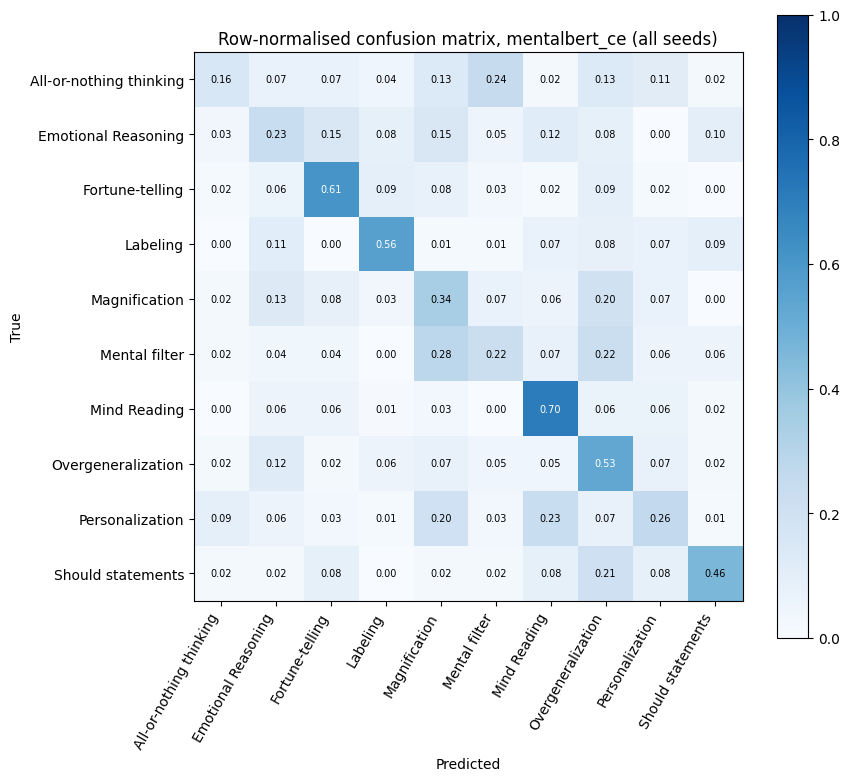

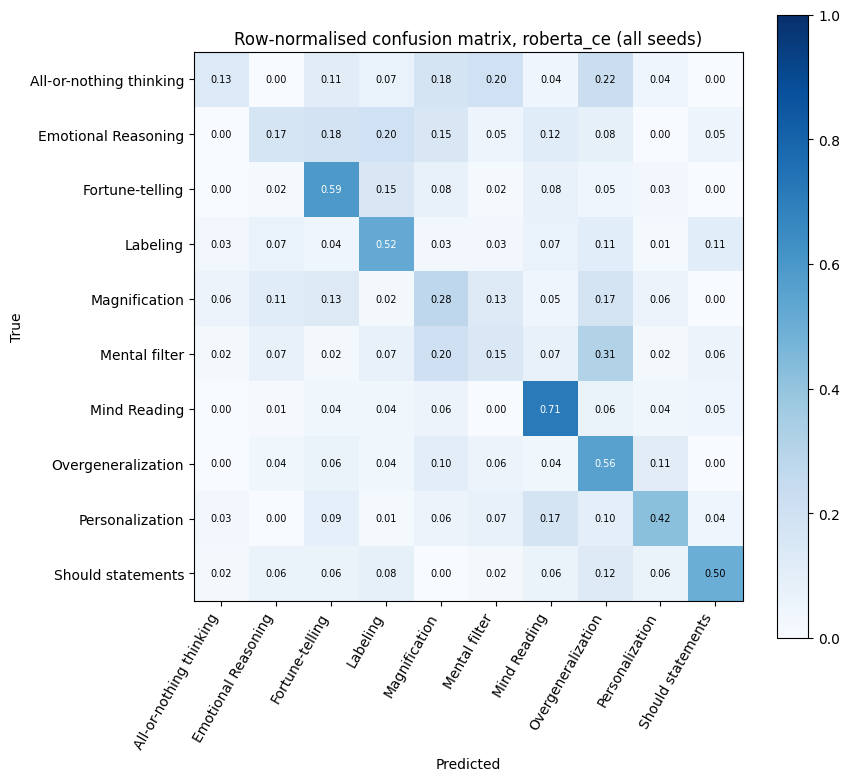

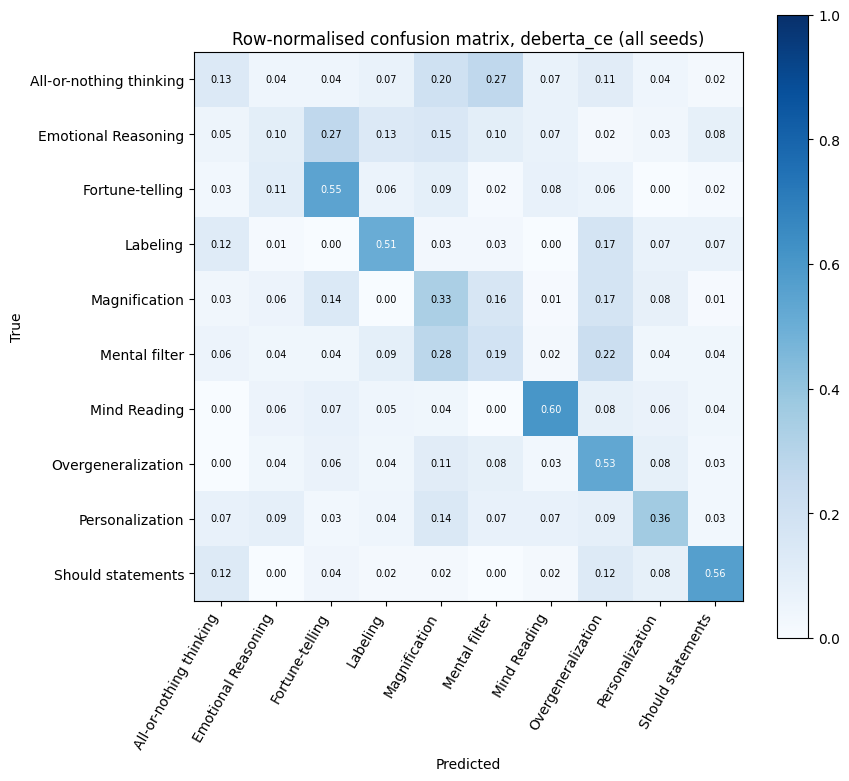

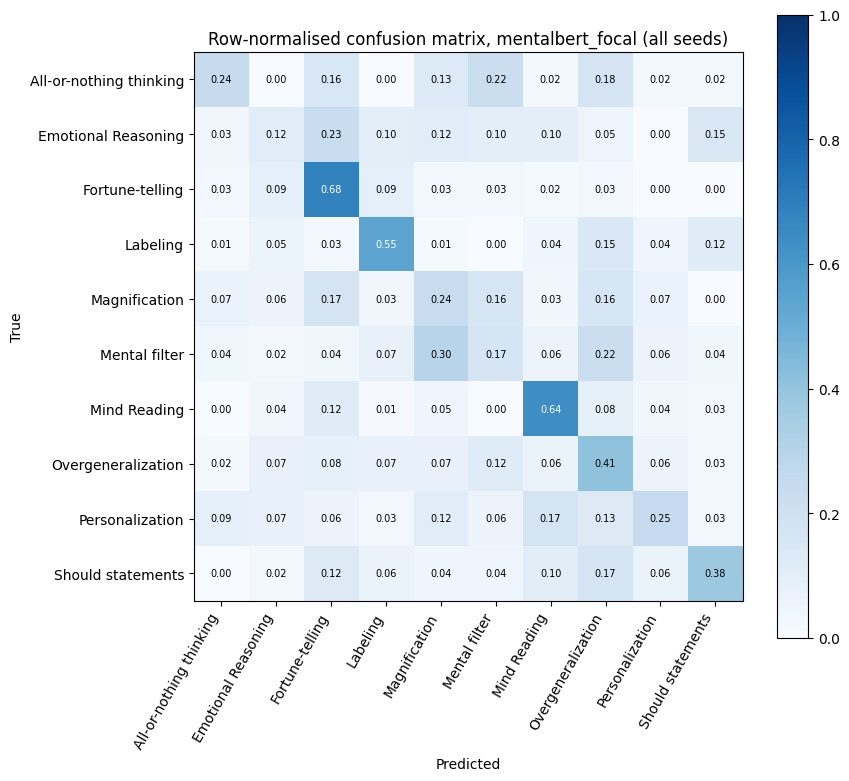

,model_a,model_b,pearson_offdiag,top10_overlap
0,mentalbert_ce,roberta_ce,0.746,7
1,mentalbert_ce,deberta_ce,0.704,7
2,mentalbert_ce,mentalbert_focal,0.799,8
3,roberta_ce,deberta_ce,0.719,6
4,roberta_ce,mentalbert_focal,0.790,7
5,deberta_ce,mentalbert_focal,0.783,6


In [11]:
import itertools
from scipy.stats import pearsonr

ENCODERS = [n for n in names if not n.startswith("tfidf")]
print("models:", ENCODERS)

cms = {}
for n in ENCODERS:
    yt = np.concatenate([y_test] * len(runs[n]))
    yp = np.concatenate(list(runs[n].values()))
    cms[n] = confusion_matrix(yt, yp, labels=range(K), normalize="true")

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cms[n], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(CLASSES, rotation=60, ha="right"); ax.set_yticklabels(CLASSES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cms[n][i,j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cms[n][i, j] > .5 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Row-normalised confusion matrix, {n} (all seeds)")
    plt.colorbar(im); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion_{n.replace(' ', '_')}.png", dpi=200); plt.show()

# How similar are the error patterns? Compare off-diagonal cells between models.
off = ~np.eye(K, dtype=bool)
rows = []
for a, b in itertools.combinations(ENCODERS, 2):
    r = pearsonr(cms[a][off], cms[b][off])[0]
    top = lambda m: set(map(tuple, np.dstack(np.unravel_index(
        np.argsort(np.where(off, m, -1).ravel())[::-1][:10], m.shape))[0]))
    rows.append((a, b, round(r, 3), len(top(cms[a]) & top(cms[b]))))
sim = pd.DataFrame(rows, columns=["model_a", "model_b", "pearson_offdiag", "top10_overlap"])
sim.to_csv(f"{OUT_DIR}/confusion_similarity.csv", index=False); display(sim)

best = names[0]
cm = cms[best] if best in cms else cm   # keep the rest of the cell working

In [12]:
# ---- per-class F1 (mean over seeds), all models ----
order = ["roberta_ce", "mentalbert_ce", "mentalbert_focal", "deberta_ce", "tfidf_lr", "tfidf_rf"]
pc = pd.DataFrame(
    {n: np.mean([f1_score(y_test, p, labels=range(K), average=None, zero_division=0)
                 for p in runs[n].values()], axis=0) for n in order if n in runs},
    index=CLASSES).round(3)
pc["test_n"] = np.bincount(y_test, minlength=K)
pc.to_csv(f"{OUT_DIR}/per_class_f1.csv")
display(pc)

# ---- top 10 confusions of the best model (pooled over seeds) ----
cm_best = cms["roberta_ce"]
tc = pd.DataFrame([(CLASSES[i], CLASSES[j], cm_best[i, j]) for i in range(K) for j in range(K) if i != j],
                  columns=["true_class", "predicted_as", "share"])
tc = tc.sort_values("share", ascending=False).head(10)
tc["share"] = (tc["share"] * 100).round(1)
tc.to_csv(f"{OUT_DIR}/top_confusions.csv", index=False)
display(tc)

,roberta_ce,mentalbert_ce,mentalbert_focal,deberta_ce,tfidf_lr,tfidf_rf,test_n
All-or-nothing thinking,0.185,0.207,0.271,0.150,0.174,0.000,15
Emotional Reasoning,0.198,0.217,0.133,0.108,0.211,0.256,20
Fortune-telling,0.494,0.566,0.497,0.468,0.286,0.286,22
Labeling,0.494,0.595,0.548,0.512,0.440,0.207,25
Magnification,0.277,0.335,0.262,0.309,0.343,0.210,29
Mental filter,0.168,0.243,0.158,0.178,0.160,0.035,18
Mind Reading,0.666,0.657,0.633,0.662,0.523,0.402,36
Overgeneralization,0.488,0.474,0.383,0.483,0.361,0.323,36
Personalization,0.452,0.286,0.289,0.371,0.429,0.211,23
Should statements,0.511,0.475,0.378,0.519,0.385,0.432,16


,true_class,predicted_as,share
51,Mental filter,Overgeneralization,31.5
6,All-or-nothing thinking,Overgeneralization,22.2
49,Mental filter,Magnification,20.4
4,All-or-nothing thinking,Mental filter,20.0
11,Emotional Reasoning,Labeling,20.0
10,Emotional Reasoning,Fortune-telling,18.3
3,All-or-nothing thinking,Magnification,17.8
78,Personalization,Mind Reading,17.4
42,Magnification,Overgeneralization,17.2
20,Fortune-telling,Labeling,15.2


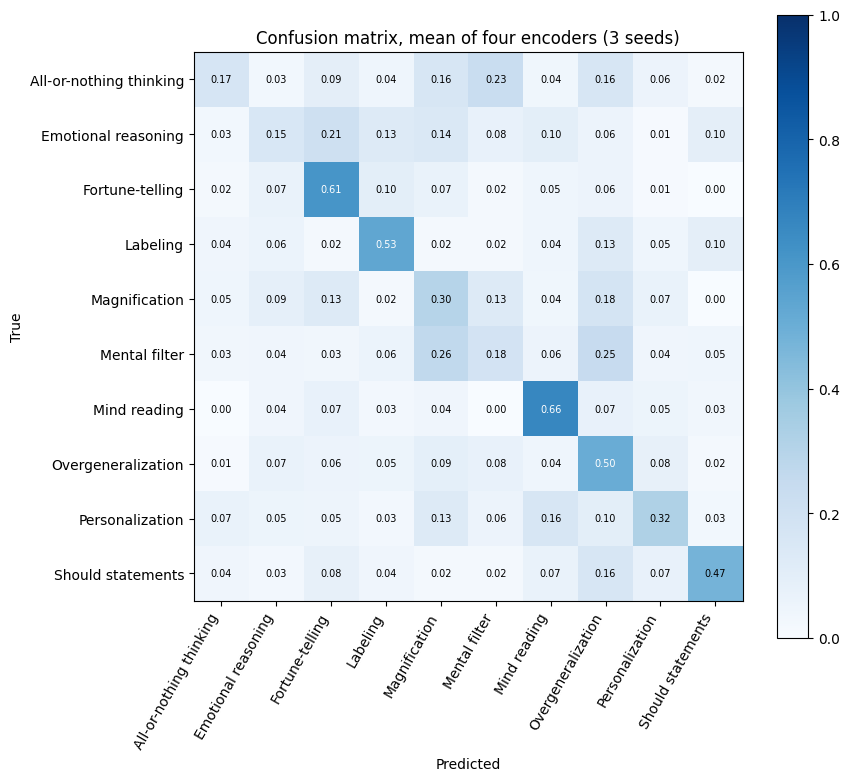

,true_class,predicted_as,share
49,Mental filter,Magnification,26.4
51,Mental filter,Overgeneralization,24.5
4,All-or-nothing thinking,Mental filter,23.3
10,Emotional reasoning,Fortune-telling,20.8
42,Magnification,Overgeneralization,17.5
78,Personalization,Mind reading,16.3
6,All-or-nothing thinking,Overgeneralization,16.1
3,All-or-nothing thinking,Magnification,16.1
88,Should statements,Overgeneralization,15.6
12,Emotional reasoning,Magnification,14.2


In [13]:
cm_mean = np.mean([cms[n] for n in ENCODERS], axis=0)   # each row still sums to 1
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_mean, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K))
lab = [c.replace("Mind Reading","Mind reading").replace("Emotional Reasoning","Emotional reasoning") for c in CLASSES]
ax.set_xticklabels(lab, rotation=60, ha="right"); ax.set_yticklabels(lab)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm_mean[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cm_mean[i, j] > .5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Confusion matrix, mean of four encoders (3 seeds)")
plt.colorbar(im); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_mean_encoders.png", dpi=200); plt.show()

tc = pd.DataFrame([(lab[i], lab[j], cm_mean[i, j]) for i in range(K) for j in range(K) if i != j],
                  columns=["true_class", "predicted_as", "share"]).sort_values("share", ascending=False).head(10)
tc["share"] = (tc["share"] * 100).round(1)
tc.to_csv(f"{OUT_DIR}/top_confusions_mean.csv", index=False); display(tc)